In [14]:
### Imports and Libraries

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import pickle
from matplotlib.lines import Line2D
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
from matplotlib.patches import Patch
from shapely.geometry import Point
from geopandas import GeoDataFrame
from ipywidgets import interact, FloatSlider

# Load the trained 3-variable GP outputs (single pickle dictionary)
with open('gp_model_Middle.pkl', 'rb') as f:
    gp_output = pickle.load(f)

section_name = gp_output['section_name']
gp_model_3v = gp_output['gp_model_3v']
scaler_X_3v = gp_output['scaler_X_3v']
scaler_y_3v = gp_output['scaler_y_3v']
X_3v = gp_output['X_3v']
y_3v = gp_output['y_3v']
y_pred_3v = gp_output['y_pred_3v']
y_std_3v = gp_output['y_std_3v']
gp_data_3v = gp_output['gp_data_3v']
input_columns_3v = gp_output['input_columns_3v']
output_column_3v = gp_output['output_column_3v']
input_label_1_3v = gp_output['input_label_1_3v']
input_label_2_3v = gp_output['input_label_2_3v']
input_label_3_3v = gp_output['input_label_3_3v']
output_label_3v = gp_output['output_label_3v']
r2_3v = gp_output['r2_3v']
rmse_3v = gp_output['rmse_3v']
mae_3v = gp_output['mae_3v']
cv_r2_mean = gp_output['cv_r2_mean']
cv_r2_std = gp_output['cv_r2_std']
cv_rmse_mean = gp_output['cv_rmse_mean']
cv_rmse_std = gp_output['cv_rmse_std']
cv_mae_mean = gp_output['cv_mae_mean']
cv_mae_std = gp_output['cv_mae_std']
output_unit_3v = gp_output['output_unit_3v']
FT_TO_M = gp_output['FT_TO_M']
reference_distance = gp_output['reference_distance']

def format_label_3v(col_name):
    """Convert column name to readable label."""
    return col_name.replace('_', ' ').title()

input_unit_1_3v = 'm'

print(f"Loaded GP outputs for section: {section_name}")
print(f"  Training points: {len(gp_data_3v)}")
print(f"  Model: {type(gp_model_3v).__name__}")
print(f"  CV R²: {cv_r2_mean:.4f} ± {cv_r2_std:.4f}")


Loaded GP outputs for section: Middle
  Training points: 1359
  Model: GaussianProcessRegressor
  CV R²: 0.6640 ± 0.0727


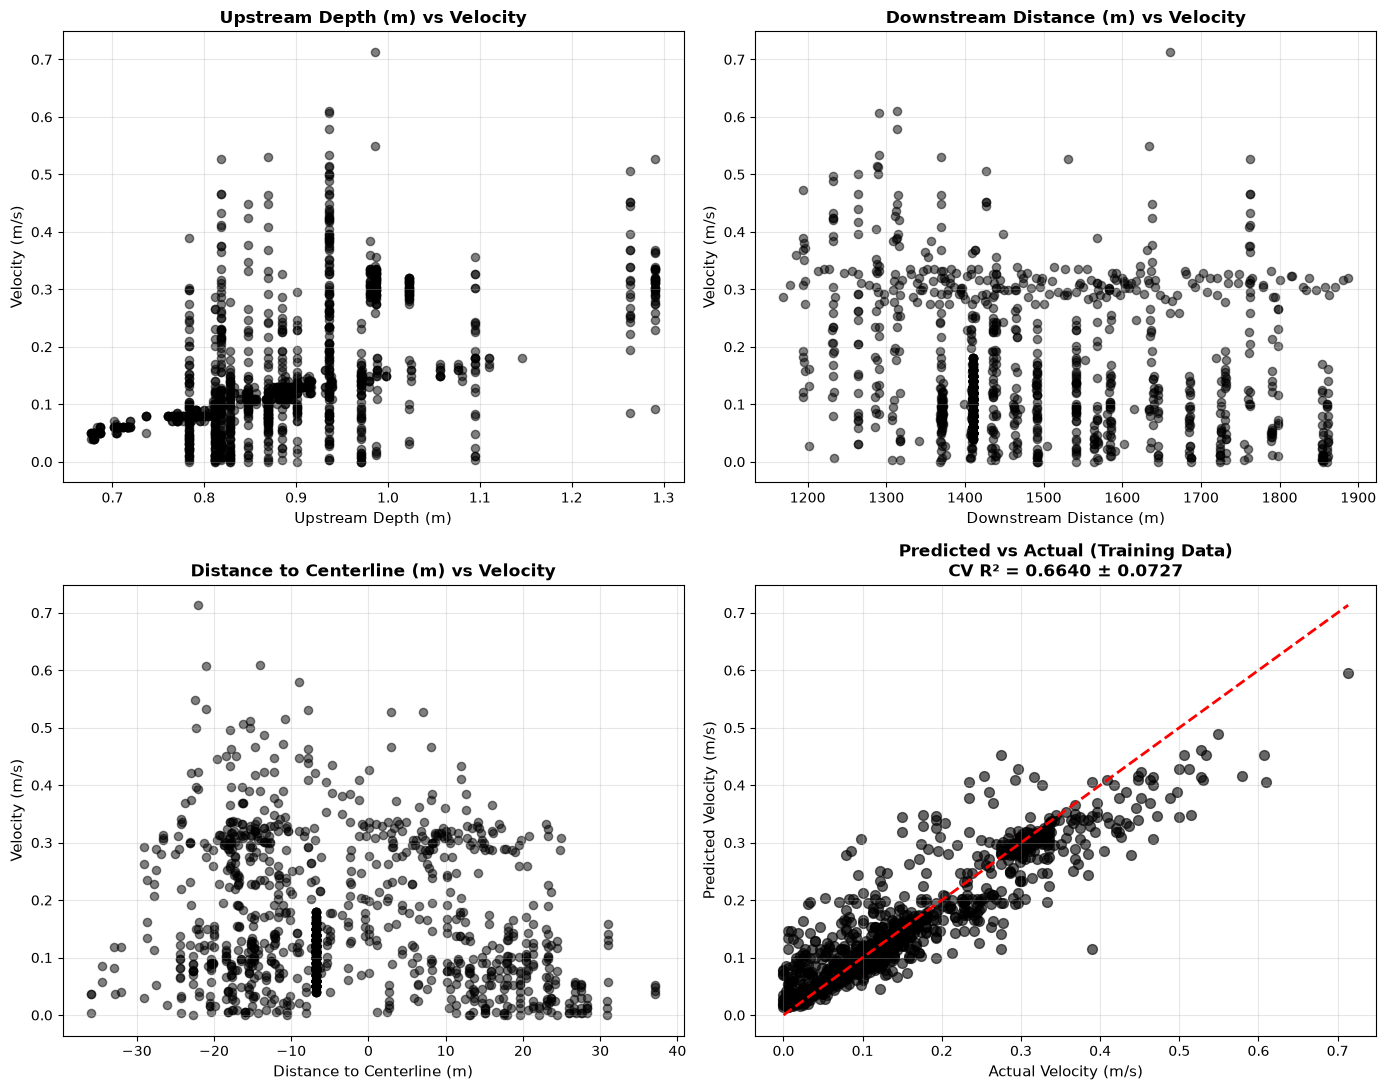


--------------------------------------------------------------------------------
Creating Interactive 2D Heatmap Visualization...
--------------------------------------------------------------------------------

✓ Interactive 2D Heatmap created successfully!
  Resolution: 50x50 grid points
  Distance To Centerline (m) range: [-37.15, 37.15] (symmetric)
  Downstream Dist (m) range: [1166.30, 1890.10]
  Actual data - Distance To Centerline (m): [-35.95, 37.15]
  Actual data - Downstream Dist (m): [1169.30, 1887.10]
  Upstream Depth slider range: [0.676, 1.291] m

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.8795750281464, continuous_update=False, description='Upstream Depth:…

<function __main__.plot_velocity_heatmap(upstream_depth)>

In [15]:
### 9) 3v Model Visualizations
# Heat map and 1-to-1 plots

# 2x2 Plot: Each input vs velocity (actual and predicted) + model verification (Predicted vs Actual)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
input_labels = [
    'Upstream Depth (m)', 
    'Downstream Distance (m)', 
    'Distance to Centerline (m)'
]
input_columns = [
    'upstream_depth', 
    'downstream_dist', 
    'distance_to_centerline'
]
inputs = [gp_data_3v[col] for col in input_columns]

# Scatter: Input vs Actual velocity (colored by sensor type only)
for idx, (ax, input_data, label) in enumerate(zip(axes.flat[:3], inputs, input_labels)):
    # Plot actual values colored by data type (Sontek=blue, HRWC Sensor=brown)
    scatter = ax.scatter(input_data, y_3v, alpha=0.5, c='black', s=35)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('Velocity (m/s)', fontsize=11)
    ax.set_title(f'{label} vs Velocity', fontsize=12, fontweight='bold')
    ax.grid(True, alpha=0.3)

# Scatter: Predicted vs Actual (model verification) - colored by sensor type
ax_pred = axes.flat[3]
ax_pred.scatter(y_3v, y_pred_3v, alpha=0.6, c='black', s=50)
ax_pred.plot([y_3v.min(), y_3v.max()], [y_3v.min(), y_3v.max()], 'r--', lw=2)
ax_pred.set_xlabel('Actual Velocity (m/s)', fontsize=11)
ax_pred.set_ylabel('Predicted Velocity (m/s)', fontsize=11)
ax_pred.set_title(f'Predicted vs Actual (Training Data)\nCV R² = {cv_r2_mean:.4f} ± {cv_r2_std:.4f}', fontsize=12, fontweight='bold')
ax_pred.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# =====================================================================
# 2D Heatmap: Velocity Predictions vs Spatial Position (Interactive)
# =====================================================================

print("\n" + "-"*80)
print("Creating Interactive 2D Heatmap Visualization...")
print("-"*80)

# Create a 2D heatmap showing velocity predictions as a function of
# downstream_dist (y-axis) and distance_to_centerline (x-axis)

# Get range for upstream_depth slider
upstream_depth_min = X_3v[:, 0].min()
upstream_depth_max = X_3v[:, 0].max()
upstream_depth_median = np.median(X_3v[:, 0])

# Create grid for distance_to_centerline (x-axis) and downstream_dist (y-axis)
n_points_heatmap = 50

# For distance_to_centerline, create symmetric range around 0 to show both sides of river
# Get the maximum absolute distance to ensure all data is captured
max_dist_to_centerline = max(abs(X_3v[:, 2].min()), abs(X_3v[:, 2].max()))
distance_to_centerline_range = np.linspace(-max_dist_to_centerline, max_dist_to_centerline, n_points_heatmap)

# Add small buffer to ensure all data points are within the range (3 meters buffer)
downstream_dist_min = X_3v[:, 1].min() - 3
downstream_dist_max = X_3v[:, 1].max() + 3
downstream_dist_range = np.linspace(downstream_dist_min, downstream_dist_max, n_points_heatmap)

# Create meshgrid
distance_to_centerline_grid, downstream_dist_grid = np.meshgrid(distance_to_centerline_range, downstream_dist_range)

# Create custom colormap that has white at 0
# Using a white-to-color gradient
colors_list = ['white', '#FEF0D9', '#FDCC8A', '#FC8D59', '#E34A33', '#B30000']
n_bins = 100
cmap_custom = LinearSegmentedColormap.from_list('custom_velocity', colors_list, N=n_bins)

# Define the interactive heatmap function
def plot_velocity_heatmap(upstream_depth):
    """
    Generate velocity heatmap for given upstream_depth value
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in feet
    """
    # Create prediction grid with fixed values for other variables
    X_heatmap = np.column_stack([
        np.full(distance_to_centerline_grid.size, upstream_depth),         # upstream_depth (from slider)
        downstream_dist_grid.ravel(),                                       # downstream_dist (varies)
        distance_to_centerline_grid.ravel()                                # distance_to_centerline (varies)
    ])
    
    # Scale the input
    X_heatmap_scaled = scaler_X_3v.transform(X_heatmap)
    
    # Make predictions
    y_heatmap_scaled = gp_model_3v.predict(X_heatmap_scaled)
    
    # Transform back to original scale
    y_heatmap = scaler_y_3v.inverse_transform(y_heatmap_scaled.reshape(-1, 1)).ravel()
    
    # Reshape for heatmap
    velocity_heatmap = y_heatmap.reshape(downstream_dist_grid.shape)
    
    # Create the heatmap figure with normal aspect ratio
    fig_heatmap, ax_heatmap = plt.subplots(figsize=(14, 10))
    
    # Create heatmap using pcolormesh
    # vmin=0 ensures 0 velocity corresponds to white color
    heatmap = ax_heatmap.pcolormesh(
        distance_to_centerline_grid, 
        downstream_dist_grid, 
        velocity_heatmap,
        cmap=cmap_custom,
        shading='auto',
        vmin=0,
        vmax=velocity_heatmap.max()
    )
    
    # Invert y-axis so 0 is at top
    ax_heatmap.invert_yaxis()
    
    # Add colorbar
    cbar = plt.colorbar(heatmap, ax=ax_heatmap)
    cbar.set_label(output_label_3v, rotation=270, labelpad=20, fontsize=13)
    
    # Overlay actual data points
    scatter_actual = ax_heatmap.scatter(
        X_3v[:, 2],  # distance_to_centerline
        X_3v[:, 1],  # downstream_dist
        c=y_3v,      # actual velocity1
        s=120,
        edgecolors='black',
        linewidths=2,
        cmap=cmap_custom,
        vmin=0,
        vmax=velocity_heatmap.max(),
        alpha=0.9,
        label='Actual Measurements',
        zorder=10
    )
    
    # Labels and title
    ax_heatmap.set_xlabel(input_label_3_3v + ' (negative = left, positive = right)', fontsize=14)
    ax_heatmap.set_ylabel(input_label_2_3v, fontsize=14)
    ax_heatmap.set_title(
        f'2D Velocity Prediction Heatmap (Interactive)\n' +
        f'{format_label_3v(input_columns_3v[0])} = {upstream_depth:.2f} {input_unit_1_3v}',
        fontsize=13,
        fontweight='bold',
        pad=20
    )
    
    ax_heatmap.legend(loc='upper right', fontsize=12, framealpha=0.9)
    ax_heatmap.grid(True, alpha=0.2, linestyle='--', color='gray')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n--- Heatmap Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.3f} {input_unit_1_3v}")
    print(f"  Predicted velocity range: [{velocity_heatmap.min():.3f}, {velocity_heatmap.max():.3f}] {output_unit_3v}")
    print(f"  Mean predicted velocity: {velocity_heatmap.mean():.3f} {output_unit_3v}")

# Create interactive widget with slider
print(f"\n✓ Interactive 2D Heatmap created successfully!")
print(f"  Resolution: {n_points_heatmap}x{n_points_heatmap} grid points")
print(f"  {input_label_3_3v} range: [{-max_dist_to_centerline:.2f}, {max_dist_to_centerline:.2f}] (symmetric)")
print(f"  {input_label_2_3v} range: [{downstream_dist_min:.2f}, {downstream_dist_max:.2f}]")
print(f"  Actual data - {input_label_3_3v}: [{X_3v[:, 2].min():.2f}, {X_3v[:, 2].max():.2f}]")
print(f"  Actual data - {input_label_2_3v}: [{X_3v[:, 1].min():.2f}, {X_3v[:, 1].max():.2f}]")
print(f"  Upstream Depth slider range: [{upstream_depth_min:.3f}, {upstream_depth_max:.3f}] {input_unit_1_3v}")
print(f"\nUse the slider below to adjust {format_label_3v(input_columns_3v[0])}:")

# Display interactive widget
interact(
    plot_velocity_heatmap,
    upstream_depth=FloatSlider(
        value=upstream_depth_median,
        min=upstream_depth_min,
        max=upstream_depth_max,
        step=(upstream_depth_max - upstream_depth_min) / 50,
        description=f'{format_label_3v(input_columns_3v[0])}:',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)


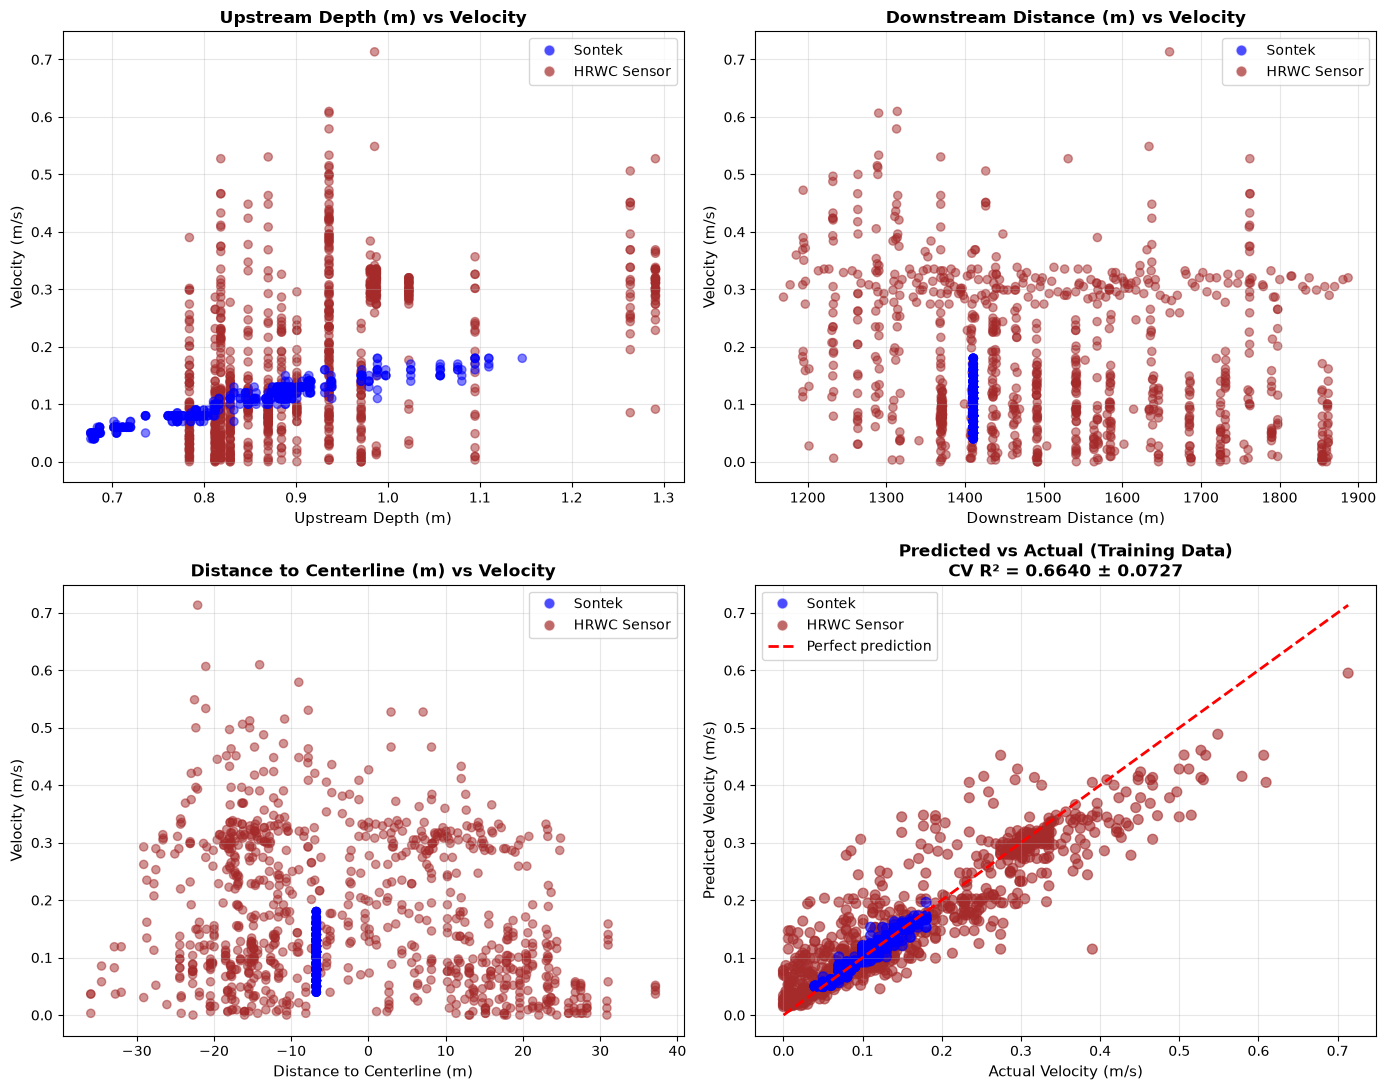


--------------------------------------------------------------------------------
Creating Interactive 2D Heatmap Visualization...
--------------------------------------------------------------------------------

✓ Interactive 2D Heatmap created successfully!
  Resolution: 50x50 grid points
  Distance To Centerline (m) range: [-37.15, 37.15] (symmetric)
  Downstream Dist (m) range: [1166.30, 1890.10]
  Actual data - Distance To Centerline (m): [-35.95, 37.15]
  Actual data - Downstream Dist (m): [1169.30, 1887.10]
  Upstream Depth slider range: [0.676, 1.291] m

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.8795750281464, continuous_update=False, description='Upstream Depth:…

<function __main__.plot_velocity_heatmap(upstream_depth)>

In [16]:
### 9) 3v Model Visualizations
# Heat map and 1-to-1 plots

# 2x2 Plot: Each input vs velocity (actual and predicted) + model verification (Predicted vs Actual)
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
input_labels = [
    'Upstream Depth (m)', 
    'Downstream Distance (m)', 
    'Distance to Centerline (m)'
]
input_columns = [
    'upstream_depth', 
    'downstream_dist', 
    'distance_to_centerline'
]
inputs = [gp_data_3v[col] for col in input_columns]

# Create color array based on Type: blue for Sontek, brown for HRWC Sensor
point_colors = np.where(gp_data_3v['Type'] == 'Sontek', 'blue', 'brown')

# Create custom legend handles for sensor types
legend_handles = [
    Line2D([0], [0], marker='o', color='w', markerfacecolor='blue', markersize=8, alpha=0.7, label='Sontek'),
    Line2D([0], [0], marker='o', color='w', markerfacecolor='brown', markersize=8, alpha=0.7, label='HRWC Sensor')
]

# Scatter: Input vs Actual velocity (colored by sensor type only)
for idx, (ax, input_data, label) in enumerate(zip(axes.flat[:3], inputs, input_labels)):
    # Plot actual values colored by data type (Sontek=blue, HRWC Sensor=brown)
    scatter = ax.scatter(input_data, y_3v, alpha=0.5, c=point_colors, s=35)
    ax.set_xlabel(label, fontsize=11)
    ax.set_ylabel('Velocity (m/s)', fontsize=11)
    ax.set_title(f'{label} vs Velocity', fontsize=12, fontweight='bold')
    ax.legend(handles=legend_handles)
    ax.grid(True, alpha=0.3)

# Scatter: Predicted vs Actual (model verification) - colored by sensor type
ax_pred = axes.flat[3]
ax_pred.scatter(y_3v, y_pred_3v, alpha=0.6, c=point_colors, s=50)
ax_pred.plot([y_3v.min(), y_3v.max()], [y_3v.min(), y_3v.max()], 'r--', lw=2)
ax_pred.set_xlabel('Actual Velocity (m/s)', fontsize=11)
ax_pred.set_ylabel('Predicted Velocity (m/s)', fontsize=11)
ax_pred.set_title(f'Predicted vs Actual (Training Data)\nCV R² = {cv_r2_mean:.4f} ± {cv_r2_std:.4f}', fontsize=12, fontweight='bold')
ax_pred.legend(handles=legend_handles + [Line2D([0], [0], color='r', linestyle='--', lw=2, label='Perfect prediction')])
ax_pred.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# =====================================================================
# 2D Heatmap: Velocity Predictions vs Spatial Position (Interactive)
# =====================================================================

print("\n" + "-"*80)
print("Creating Interactive 2D Heatmap Visualization...")
print("-"*80)

# Create a 2D heatmap showing velocity predictions as a function of
# downstream_dist (y-axis) and distance_to_centerline (x-axis)

# Get range for upstream_depth slider
upstream_depth_min = X_3v[:, 0].min()
upstream_depth_max = X_3v[:, 0].max()
upstream_depth_median = np.median(X_3v[:, 0])

# Create grid for distance_to_centerline (x-axis) and downstream_dist (y-axis)
n_points_heatmap = 50

# For distance_to_centerline, create symmetric range around 0 to show both sides of river
# Get the maximum absolute distance to ensure all data is captured
max_dist_to_centerline = max(abs(X_3v[:, 2].min()), abs(X_3v[:, 2].max()))
distance_to_centerline_range = np.linspace(-max_dist_to_centerline, max_dist_to_centerline, n_points_heatmap)

# Add small buffer to ensure all data points are within the range (3 meters buffer)
downstream_dist_min = X_3v[:, 1].min() - 3
downstream_dist_max = X_3v[:, 1].max() + 3
downstream_dist_range = np.linspace(downstream_dist_min, downstream_dist_max, n_points_heatmap)

# Create meshgrid
distance_to_centerline_grid, downstream_dist_grid = np.meshgrid(distance_to_centerline_range, downstream_dist_range)

# Create custom colormap that has white at 0
# Using a white-to-color gradient
colors_list = ['white', '#FEF0D9', '#FDCC8A', '#FC8D59', '#E34A33', '#B30000']
n_bins = 100
cmap_custom = LinearSegmentedColormap.from_list('custom_velocity', colors_list, N=n_bins)

# Define the interactive heatmap function
def plot_velocity_heatmap(upstream_depth):
    """
    Generate velocity heatmap for given upstream_depth value
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in feet
    """
    # Create prediction grid with fixed values for other variables
    X_heatmap = np.column_stack([
        np.full(distance_to_centerline_grid.size, upstream_depth),         # upstream_depth (from slider)
        downstream_dist_grid.ravel(),                                       # downstream_dist (varies)
        distance_to_centerline_grid.ravel()                                # distance_to_centerline (varies)
    ])
    
    # Scale the input
    X_heatmap_scaled = scaler_X_3v.transform(X_heatmap)
    
    # Make predictions
    y_heatmap_scaled = gp_model_3v.predict(X_heatmap_scaled)
    
    # Transform back to original scale
    y_heatmap = scaler_y_3v.inverse_transform(y_heatmap_scaled.reshape(-1, 1)).ravel()
    
    # Reshape for heatmap
    velocity_heatmap = y_heatmap.reshape(downstream_dist_grid.shape)
    
    # Create the heatmap figure with normal aspect ratio
    fig_heatmap, ax_heatmap = plt.subplots(figsize=(14, 10))
    
    # Create heatmap using pcolormesh
    # vmin=0 ensures 0 velocity corresponds to white color
    heatmap = ax_heatmap.pcolormesh(
        distance_to_centerline_grid, 
        downstream_dist_grid, 
        velocity_heatmap,
        cmap=cmap_custom,
        shading='auto',
        vmin=0,
        vmax=velocity_heatmap.max()
    )
    
    # Invert y-axis so 0 is at top
    ax_heatmap.invert_yaxis()
    
    # Add colorbar
    cbar = plt.colorbar(heatmap, ax=ax_heatmap)
    cbar.set_label(output_label_3v, rotation=270, labelpad=20, fontsize=13)
    
    # Overlay actual data points
    scatter_actual = ax_heatmap.scatter(
        X_3v[:, 2],  # distance_to_centerline
        X_3v[:, 1],  # downstream_dist
        c=y_3v,      # actual velocity1
        s=120,
        edgecolors='black',
        linewidths=2,
        cmap=cmap_custom,
        vmin=0,
        vmax=velocity_heatmap.max(),
        alpha=0.9,
        label='Actual Measurements',
        zorder=10
    )
    
    # Labels and title
    ax_heatmap.set_xlabel(input_label_3_3v + ' (negative = left, positive = right)', fontsize=14)
    ax_heatmap.set_ylabel(input_label_2_3v, fontsize=14)
    ax_heatmap.set_title(
        f'2D Velocity Prediction Heatmap (Interactive)\n' +
        f'{format_label_3v(input_columns_3v[0])} = {upstream_depth:.2f} {input_unit_1_3v}',
        fontsize=13,
        fontweight='bold',
        pad=20
    )
    
    ax_heatmap.legend(loc='upper right', fontsize=12, framealpha=0.9)
    ax_heatmap.grid(True, alpha=0.2, linestyle='--', color='gray')
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n--- Heatmap Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.3f} {input_unit_1_3v}")
    print(f"  Predicted velocity range: [{velocity_heatmap.min():.3f}, {velocity_heatmap.max():.3f}] {output_unit_3v}")
    print(f"  Mean predicted velocity: {velocity_heatmap.mean():.3f} {output_unit_3v}")

# Create interactive widget with slider
print(f"\n✓ Interactive 2D Heatmap created successfully!")
print(f"  Resolution: {n_points_heatmap}x{n_points_heatmap} grid points")
print(f"  {input_label_3_3v} range: [{-max_dist_to_centerline:.2f}, {max_dist_to_centerline:.2f}] (symmetric)")
print(f"  {input_label_2_3v} range: [{downstream_dist_min:.2f}, {downstream_dist_max:.2f}]")
print(f"  Actual data - {input_label_3_3v}: [{X_3v[:, 2].min():.2f}, {X_3v[:, 2].max():.2f}]")
print(f"  Actual data - {input_label_2_3v}: [{X_3v[:, 1].min():.2f}, {X_3v[:, 1].max():.2f}]")
print(f"  Upstream Depth slider range: [{upstream_depth_min:.3f}, {upstream_depth_max:.3f}] {input_unit_1_3v}")
print(f"\nUse the slider below to adjust {format_label_3v(input_columns_3v[0])}:")

# Display interactive widget
interact(
    plot_velocity_heatmap,
    upstream_depth=FloatSlider(
        value=upstream_depth_median,
        min=upstream_depth_min,
        max=upstream_depth_max,
        step=(upstream_depth_max - upstream_depth_min) / 50,
        description=f'{format_label_3v(input_columns_3v[0])}:',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)


STEP 1: Setting up centerline reference
Centerline geometry type: LineString
Reference distance along centerline: 11045.64 meters

Diagnostic check:
Min downstream_dist in gp_data_3v: 1169.30
Expected: if downstream_dist was calculated correctly, min should be ~0
Actual min downstream_dist value: 1169.301337

STEP 2: Defining inverse transformation function
✓ Inverse transformation function defined

STEP 3: Creating grid in model input space
Downstream distance range: [1169.30, 1887.10] m
Centerline distance range: [-35.95, 37.15] m
✓ Grid created: 50 × 50 = 2500 points

STEP 4: Evaluating GP model on grid
Using fixed upstream depth: 0.893 m
✓ Predictions complete
Velocity range: [-0.0261, 0.4183] m/s (before clipping)
Velocity range: [0.0000, 0.4183] m/s (after clipping negative values)

STEP 5: Transforming grid to spatial coordinates (geometric inversion)
✓ Grid transformed to spatial coordinates
Easting range: [13244514.51, 13245374.99] ft
Northing range: [318472.85, 320753.18] ft


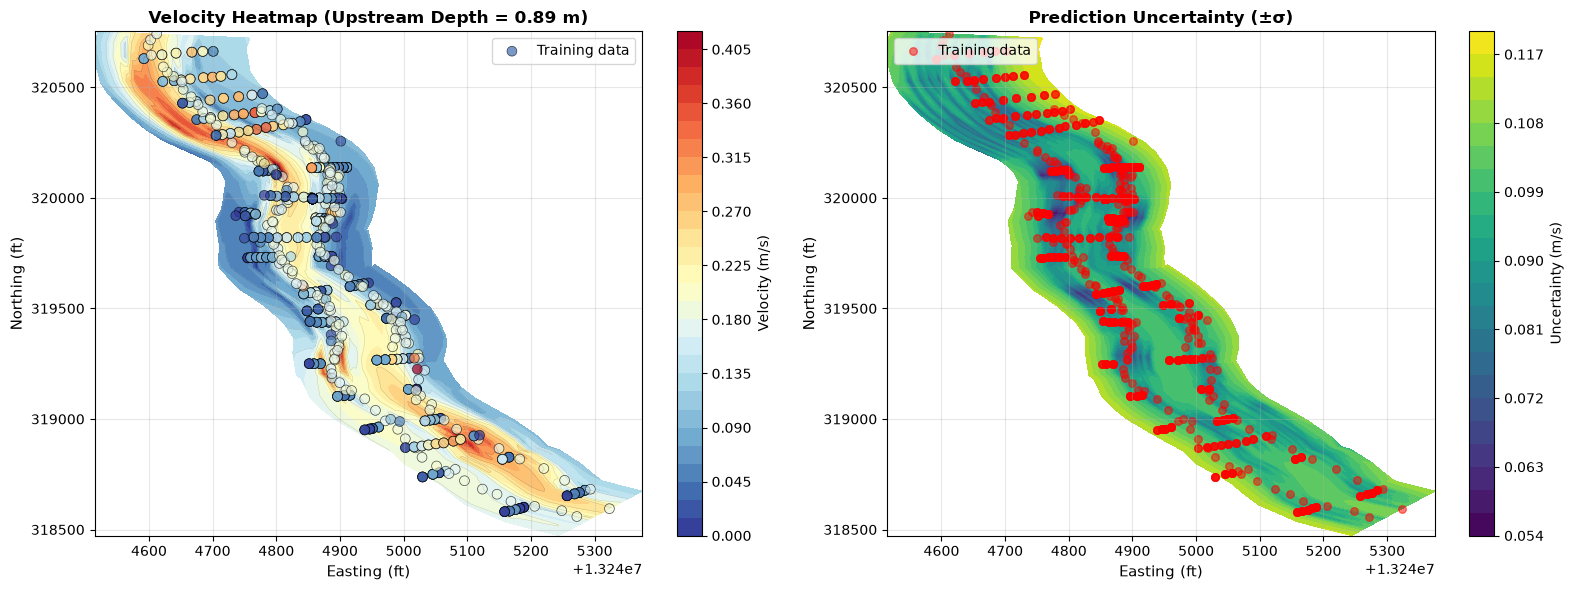

✓ Visualization complete!

STEP 7 (Optional): Exporting results


In [17]:
### 10) Project Model Back to NAD 1983 State Plane Michigan South (feet)

# Option to use mean upstream depth from training data
upstream_depth_value = gp_data_3v['upstream_depth'].mean()

# Define grid resolution (adjust as needed for smoothness vs computation time)
grid_resolution = 50  # Number of points along each dimension (increased for smoother results)

# =====================================================================
# STEP 1: GET REFERENCE DISTANCE AND CENTERLINE
# =====================================================================

print("="*80)
print("STEP 1: Setting up centerline reference")
print("="*80)

# Get the centerline geometry
centerline = gpd.read_file("mapping/centerline_union_Middle.geojson")
centerline_geom = centerline.geometry.iloc[0]

print(f"Centerline geometry type: {centerline_geom.geom_type}")

# from above dict of GP pickle
print(f"Reference distance along centerline: {reference_distance:.2f} meters")

# DIAGNOSTIC: Check if reference_distance matches what was used to create downstream_dist
print(f"\nDiagnostic check:")
print(f"Min downstream_dist in gp_data_3v: {gp_data_3v['downstream_dist'].min():.2f}")
print(f"Expected: if downstream_dist was calculated correctly, min should be ~0")
print(f"Actual min downstream_dist value: {gp_data_3v['downstream_dist'].min():.6f}")

# =====================================================================
# STEP 2: DEFINE INVERSE TRANSFORMATION FUNCTION
# =====================================================================

print("\n" + "="*80)
print("STEP 2: Defining inverse transformation function")
print("="*80)

def model_to_spatial(downstream_dist, distance_to_centerline):
    """
    Transform from model input space to spatial coordinates using geometric inversion.
    
    Parameters:
    -----------
    downstream_dist : array-like
        Downstream distance(s) in meters (from SI-converted gp_data_3v)
    distance_to_centerline : array-like
        Signed distance to centerline in meters
        (negative = left of centerline, positive = right)
    
    Returns:
    --------
    easting, northing : arrays
        Spatial coordinates (in feet, matching the CRS)
    """
    # Ensure inputs are numpy arrays
    downstream_dist = np.atleast_1d(downstream_dist)
    distance_to_centerline = np.atleast_1d(distance_to_centerline)
    
    easting_list = []
    northing_list = []
    
    # CRITICAL FIX: Convert meters back to feet to match CRS units
    # The centerline geometry and reference_distance are in feet (State Plane CRS)
    # but ds_dist and cl_dist from gp_data_3v are in meters (converted in Cell 29)
    M_TO_FT = 1.0 / FT_TO_M  # = 1/0.3048 ≈ 3.28084
    
    for ds_dist, cl_dist in zip(downstream_dist, distance_to_centerline):
        # Convert from meters to feet before using with centerline geometry
        ds_dist_ft = ds_dist * M_TO_FT
        cl_dist_ft = cl_dist * M_TO_FT
        
        # Step 1: Get point on centerline at this downstream distance
        distance_along_line = reference_distance + ds_dist_ft  # both now in feet
        point_on_centerline = centerline_geom.interpolate(distance_along_line)
        
        # Step 2: Get the direction along the centerline at this point
        # by sampling two nearby points and computing the tangent vector
        epsilon = 0.1  # Small offset for numerical differentiation (in feet)
        p1 = centerline_geom.interpolate(max(0, distance_along_line - epsilon))
        p2 = centerline_geom.interpolate(min(centerline_geom.length, distance_along_line + epsilon))
        
        # Tangent vector (direction along centerline)
        tangent_x = p2.x - p1.x
        tangent_y = p2.y - p1.y
        tangent_length = np.sqrt(tangent_x**2 + tangent_y**2)
        
        if tangent_length < 1e-6:
            # Degenerate case, use the point as-is
            easting_list.append(point_on_centerline.x)
            northing_list.append(point_on_centerline.y)
        else:
            # Normalize tangent vector
            tangent_x /= tangent_length
            tangent_y /= tangent_length
            
            # Perpendicular vector (rotated 90 degrees counterclockwise from tangent)
            # This points to the left of the centerline direction
            perp_x = -tangent_y
            perp_y = tangent_x
            
            # Apply the perpendicular offset (both in feet now)
            final_x = point_on_centerline.x + perp_x * cl_dist_ft
            final_y = point_on_centerline.y + perp_y * cl_dist_ft
            
            easting_list.append(final_x)
            northing_list.append(final_y)
    
    return np.array(easting_list), np.array(northing_list)

print("✓ Inverse transformation function defined")

# =====================================================================
# STEP 3: CREATE GRID IN MODEL INPUT SPACE
# =====================================================================

print("\n" + "="*80)
print("STEP 3: Creating grid in model input space")
print("="*80)

# Define grid resolution (adjust as needed for smoothness vs computation time)
grid_resolution = 50  # Number of points along each dimension (increased for smoother results)

# Get ranges from training data
downstream_min = gp_data_3v['downstream_dist'].min()
downstream_max = gp_data_3v['downstream_dist'].max()
centerline_min = gp_data_3v['distance_to_centerline'].min()
centerline_max = gp_data_3v['distance_to_centerline'].max()

print(f"Downstream distance range: [{downstream_min:.2f}, {downstream_max:.2f}] m")
print(f"Centerline distance range: [{centerline_min:.2f}, {centerline_max:.2f}] m")

# Create 1D arrays for grid
downstream_grid_1d = np.linspace(downstream_min, downstream_max, grid_resolution)
centerline_grid_1d = np.linspace(centerline_min, centerline_max, grid_resolution)

# Create 2D mesh grid
downstream_mesh, centerline_mesh = np.meshgrid(downstream_grid_1d, centerline_grid_1d)

print(f"✓ Grid created: {grid_resolution} × {grid_resolution} = {grid_resolution**2} points")

# =====================================================================
# STEP 4: EVALUATE GP MODEL ON GRID
# =====================================================================

print("\n" + "="*80)
print("STEP 4: Evaluating GP model on grid")
print("="*80)

# Flatten grid for prediction
downstream_flat = downstream_mesh.flatten()
centerline_flat = centerline_mesh.flatten()

upstream_depth_value = upstream_depth_value # set above for interactive setup BUT must be converted

print(f"Using fixed upstream depth: {upstream_depth_value:.3f} m")

# Create input array with all three dimensions
X_grid = np.column_stack([
    np.full_like(downstream_flat, upstream_depth_value),  # upstream_depth (fixed)
    downstream_flat,
    centerline_flat
])

# Scale inputs using the same scaler from training
X_grid_scaled = scaler_X_3v.transform(X_grid)

# Get predictions from GP
velocity_pred_scaled, velocity_std_scaled = gp_model_3v.predict(X_grid_scaled, return_std=True)

# Inverse transform to original scale
velocity_pred = scaler_y_3v.inverse_transform(velocity_pred_scaled.reshape(-1, 1)).ravel()
velocity_std = velocity_std_scaled * scaler_y_3v.scale_

# Reshape back to 2D grid
velocity_grid = velocity_pred.reshape(downstream_mesh.shape)
velocity_std_grid = velocity_std.reshape(downstream_mesh.shape)

# Clip negative velocities to zero (physically unrealistic)
velocity_grid = np.clip(velocity_grid, 0, None)

print(f"✓ Predictions complete")
print(f"Velocity range: [{velocity_pred.min():.4f}, {velocity_pred.max():.4f}] m/s (before clipping)")
print(f"Velocity range: [{velocity_grid.min():.4f}, {velocity_grid.max():.4f}] m/s (after clipping negative values)")

# =====================================================================
# STEP 5: TRANSFORM GRID TO SPATIAL COORDINATES
# =====================================================================

print("\n" + "="*80)
print("STEP 5: Transforming grid to spatial coordinates (geometric inversion)")
print("="*80)

# Transform grid points to spatial coordinates using geometric inversion
easting_grid_flat, northing_grid_flat = model_to_spatial(downstream_flat, centerline_flat)
easting_grid = easting_grid_flat.reshape(downstream_mesh.shape)
northing_grid = northing_grid_flat.reshape(downstream_mesh.shape)

print(f"✓ Grid transformed to spatial coordinates")
print(f"Easting range: [{easting_grid.min():.2f}, {easting_grid.max():.2f}] ft")
print(f"Northing range: [{northing_grid.min():.2f}, {northing_grid.max():.2f}] ft")

# =====================================================================
# STEP 6: VISUALIZE SPATIAL HEATMAP
# =====================================================================

print("\n" + "="*80)
print("STEP 6: Creating spatial heatmap visualization")
print("="*80)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Heatmap in spatial coordinates
contourf = ax1.contourf(easting_grid, northing_grid, velocity_grid, levels=30, cmap='RdYlBu_r')
contour = ax1.contour(easting_grid, northing_grid, velocity_grid, levels=15, colors='black', alpha=0.2, linewidths=0.3)

# Overlay training data points
scatter = ax1.scatter(gp_data_3v['Easting'], gp_data_3v['Northing'], 
                      c=gp_data_3v['Velocity'], s=50, cmap='RdYlBu_r', 
                      edgecolors='black', linewidth=0.5, alpha=0.7, label='Training data')

ax1.set_xlabel('Easting (ft)', fontsize=11)
ax1.set_ylabel('Northing (ft)', fontsize=11)
ax1.set_title(f'Velocity Heatmap (Upstream Depth = {upstream_depth_value:.2f} m)', fontsize=12, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)
cbar1 = plt.colorbar(contourf, ax=ax1, label='Velocity (m/s)')

# Plot 2: Prediction uncertainty in spatial coordinates
contourf_std = ax2.contourf(easting_grid, northing_grid, velocity_std_grid, levels=20, cmap='viridis')
ax2.scatter(gp_data_3v['Easting'], gp_data_3v['Northing'], 
           s=30, c='red', alpha=0.5, label='Training data')
ax2.set_xlabel('Easting (ft)', fontsize=11)
ax2.set_ylabel('Northing (ft)', fontsize=11)
ax2.set_title('Prediction Uncertainty (±σ)', fontsize=12, fontweight='bold')
ax2.legend(loc='upper left')
ax2.grid(True, alpha=0.3)
cbar2 = plt.colorbar(contourf_std, ax=ax2, label='Uncertainty (m/s)')

plt.tight_layout()
plt.show()

print(f"✓ Visualization complete!")

# =====================================================================
# OPTIONAL: EXPORT RESULTS TO GEOJSON OR CSV
# =====================================================================

print("\n" + "="*80)
print("STEP 7 (Optional): Exporting results")
print("="*80)

# Create a dataframe with grid results
results_df = pd.DataFrame({
    'easting': easting_grid_flat,
    'northing': northing_grid_flat,
    'velocity': velocity_pred,
    'velocity_uncertainty': velocity_std,
    'downstream_dist': downstream_flat,
    'distance_to_centerline': centerline_flat
})


In [18]:
### 11) Interactive Spatial GP Model Visualization with Upstream Depth Slider
# =====================================================================
# Interactive visualization of projected GP model output in spatial coordinates
# Uses single slider for upstream depth to update both velocity and uncertainty plots
# =====================================================================
fontX = 1.5

print("="*80)
print("INTERACTIVE SPATIAL GP MODEL VISUALIZATION")
print("="*80)

# Get upstream depth range from training data (already in SI units - meters)
upstream_depth_min_spatial = gp_data_3v['upstream_depth'].min()
upstream_depth_max_spatial = gp_data_3v['upstream_depth'].max()
upstream_depth_median_spatial = gp_data_3v['upstream_depth'].median()

print(f"\nUpstream Depth Range: [{upstream_depth_min_spatial:.3f}, {upstream_depth_max_spatial:.3f}] m")
print(f"Grid Resolution: {grid_resolution} × {grid_resolution} = {grid_resolution**2} points")

def plot_spatial_heatmap_interactive(upstream_depth):
    """
    Generate interactive spatial heatmap for given upstream_depth value.
    Shows both velocity predictions and uncertainty in spatial coordinates.
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in meters (SI units)
    """
    # Create input array with the selected upstream depth
    X_grid_interactive = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),  # upstream_depth (from slider)
        downstream_flat,                                 # downstream_dist
        centerline_flat                                  # distance_to_centerline
    ])
    
    # Scale inputs using the same scaler from training
    X_grid_interactive_scaled = scaler_X_3v.transform(X_grid_interactive)
    
    # Get predictions from GP with uncertainty
    velocity_pred_interactive_scaled, velocity_std_interactive_scaled = gp_model_3v.predict(
        X_grid_interactive_scaled, return_std=True
    )
    
    # Inverse transform to original scale
    velocity_pred_interactive = scaler_y_3v.inverse_transform(
        velocity_pred_interactive_scaled.reshape(-1, 1)
    ).ravel()
    velocity_std_interactive = velocity_std_interactive_scaled * scaler_y_3v.scale_
    
    # Reshape back to 2D grid
    velocity_grid_interactive = velocity_pred_interactive.reshape(downstream_mesh.shape)
    velocity_std_grid_interactive = velocity_std_interactive.reshape(downstream_mesh.shape)
    
    # Clip negative velocities to zero (physically unrealistic)
    velocity_grid_interactive = np.clip(velocity_grid_interactive, 0, None)
    
    # Create figure with two subplots
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(20, 10))
    
    # ===== Plot 1: Velocity Heatmap in Spatial Coordinates =====
    contourf1 = ax1.contourf(
        easting_grid, northing_grid, velocity_grid_interactive, 
        levels=30, cmap='viridis' ########################3
    )
    contour1 = ax1.contour(
        easting_grid, northing_grid, velocity_grid_interactive, 
        levels=15, colors='black', alpha=0.2, linewidths=0.3
    )
    '''
    # Overlay training data points
    scatter1 = ax1.scatter(
        gp_data_3v['Easting'], gp_data_3v['Northing'], 
        c=gp_data_3v['Velocity'], s=60, cmap='viridis', 
        edgecolors='black', linewidth=0.8, alpha=0.8, 
        label='Training Data', zorder=10
    )
    '''
    ax1.set_xlabel('Easting (ft)', fontsize=12*fontX)
    ax1.set_ylabel('Northing (ft)', fontsize=12*fontX)
    ax1.set_title(
        f'Velocity Prediction (Spatial Coordinates)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=13*fontX, fontweight='bold'
    )
    ax1.legend(loc='upper right', fontsize=10*fontX, framealpha=0.9)
    ax1.grid(True, alpha=0.3)
    cbar1 = plt.colorbar(contourf1, ax=ax1)
    cbar1.set_label('Velocity (m/s)', fontsize=11*fontX)
    
    # ===== Plot 2: Prediction Uncertainty in Spatial Coordinates =====
    contourf2 = ax2.contourf(
        easting_grid, northing_grid, velocity_std_grid_interactive, 
        levels=20, cmap='viridis'
    )
    '''
    # Overlay training data points
    scatter2 = ax2.scatter(
        gp_data_3v['Easting'], gp_data_3v['Northing'], 
        s=40, c='red', alpha=0.6, label='Training Data', zorder=10
    )
    '''
    ax2.set_xlabel('Easting (ft)', fontsize=12*fontX)
    ax2.set_ylabel('Northing (ft)', fontsize=12*fontX)
    ax2.set_title(
        f'Prediction Uncertainty (±σ)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=13*fontX, fontweight='bold'
    )
    ax2.legend(loc='upper left', fontsize=10*fontX, framealpha=0.9)
    ax2.grid(True, alpha=0.3)
    cbar2 = plt.colorbar(contourf2, ax=ax2)
    cbar2.set_label('Uncertainty (m/s)', fontsize=11*fontX)
    
    plt.tight_layout()
    plt.show()
    
    # Print statistics
    print(f"\n--- Model Output Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.4f} m ({upstream_depth / FT_TO_M:.3f} ft)")
    print(f"  Velocity Range: [{velocity_grid_interactive.min():.4f}, {velocity_grid_interactive.max():.4f}] m/s")
    print(f"  Mean Velocity: {velocity_grid_interactive.mean():.4f} m/s")
    print(f"  Uncertainty Range: [{velocity_std_grid_interactive.min():.4f}, {velocity_std_grid_interactive.max():.4f}] m/s")
    print(f"  Mean Uncertainty: {velocity_std_grid_interactive.mean():.4f} m/s")

# Create interactive widget with slider
print(f"\n✓ Interactive Spatial Visualization Ready!")
print(f"\nUse the slider below to adjust Upstream Depth:")

interact(
    plot_spatial_heatmap_interactive,
    upstream_depth=FloatSlider(
        value=upstream_depth_median_spatial,
        min=upstream_depth_min_spatial,
        max=upstream_depth_max_spatial,
        step=(upstream_depth_max_spatial - upstream_depth_min_spatial) / 50,
        description='Upstream Depth (m):',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)

INTERACTIVE SPATIAL GP MODEL VISUALIZATION

Upstream Depth Range: [0.676, 1.291] m
Grid Resolution: 50 × 50 = 2500 points

✓ Interactive Spatial Visualization Ready!

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.8795750281464, continuous_update=False, description='Upstream Depth …

<function __main__.plot_spatial_heatmap_interactive(upstream_depth)>

In [19]:
### 12) Interactive Binary Threshold Visualization (Velocity > 0.2 m/s)
# =====================================================================
# Binary color visualization: Red = velocity > threshold, Green = velocity <= threshold
# Uses single slider for upstream depth
# =====================================================================
fontX = 1.5

print("="*80)
print("INTERACTIVE BINARY THRESHOLD VISUALIZATION")
print("="*80)

# Define velocity threshold
VELOCITY_THRESHOLD = 0.2  # m/s

print(f"\nVelocity Threshold: {VELOCITY_THRESHOLD} m/s")
print(f"  Red = velocity > {VELOCITY_THRESHOLD} m/s (high velocity)")
print(f"  Green = velocity ≤ {VELOCITY_THRESHOLD} m/s (low velocity)")

# Get upstream depth range from training data (already in SI units - meters)
upstream_depth_min_binary = gp_data_3v['upstream_depth'].min()
upstream_depth_max_binary = gp_data_3v['upstream_depth'].max()
upstream_depth_median_binary = gp_data_3v['upstream_depth'].median()

# Create binary colormap: 0 = green, 1 = red
binary_cmap = ListedColormap(['#2ecc71', '#e74c3c'])  # Green, Red

def calculate_area_below_threshold(upstream_depth, return_bounds=False):
    """Calculate percentage of area below velocity threshold for given upstream depth.
    
    If return_bounds=True, also returns lower and upper bounds based on GP uncertainty.
    """
    X_grid = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),
        downstream_flat,
        centerline_flat
    ])
    X_grid_scaled = scaler_X_3v.transform(X_grid)
    
    # Get predictions with uncertainty
    vel_pred_scaled, vel_std_scaled = gp_model_3v.predict(X_grid_scaled, return_std=True)
    vel_pred = scaler_y_3v.inverse_transform(vel_pred_scaled.reshape(-1, 1)).ravel()
    vel_std = vel_std_scaled * scaler_y_3v.scale_
    
    vel_pred = np.clip(vel_pred, 0, None)
    area_mean = ((vel_pred <= VELOCITY_THRESHOLD).sum() / len(vel_pred)) * 100
    
    if return_bounds:
        # Lower bound: using (vel + std) - fewer points will be below threshold
        vel_upper = np.clip(vel_pred + vel_std, 0, None)
        area_lower = ((vel_upper <= VELOCITY_THRESHOLD).sum() / len(vel_upper)) * 100
        
        # Upper bound: using (vel - std) - more points will be below threshold
        vel_lower = np.clip(vel_pred - vel_std, 0, None)
        area_upper = ((vel_lower <= VELOCITY_THRESHOLD).sum() / len(vel_lower)) * 100
        
        return area_mean, area_lower, area_upper
    
    return area_mean

# Pre-calculate area for all depth values with uncertainty bounds (used for line plot in next cell)
upstream_depth_values = np.linspace(upstream_depth_min_binary, upstream_depth_max_binary, 50)
area_below_threshold_values = []
area_lower_bounds = []
area_upper_bounds = []

for d in upstream_depth_values:
    mean, lower, upper = calculate_area_below_threshold(d, return_bounds=True)
    area_below_threshold_values.append(mean)
    area_lower_bounds.append(lower)
    area_upper_bounds.append(upper)

print(f"✓ Pre-calculated area with uncertainty for {len(upstream_depth_values)} depth values")

def plot_binary_threshold_interactive(upstream_depth):
    """
    Generate interactive binary threshold heatmap for given upstream_depth value.
    Red indicates velocity above threshold, Green indicates velocity at or below threshold.
    
    Parameters:
    -----------
    upstream_depth : float
        Upstream depth value in meters (SI units)
    """
    # Create input array with the selected upstream depth
    X_grid_binary = np.column_stack([
        np.full_like(downstream_flat, upstream_depth),  # upstream_depth (from slider)
        downstream_flat,                                 # downstream_dist
        centerline_flat                                  # distance_to_centerline
    ])
    
    # Scale inputs using the same scaler from training
    X_grid_binary_scaled = scaler_X_3v.transform(X_grid_binary)
    
    # Get predictions from GP
    velocity_pred_binary_scaled = gp_model_3v.predict(X_grid_binary_scaled)
    
    # Inverse transform to original scale
    velocity_pred_binary = scaler_y_3v.inverse_transform(
        velocity_pred_binary_scaled.reshape(-1, 1)
    ).ravel()
    
    # Reshape back to 2D grid
    velocity_grid_binary = velocity_pred_binary.reshape(downstream_mesh.shape)
    
    # Clip negative velocities to zero
    velocity_grid_binary = np.clip(velocity_grid_binary, 0, None)
    
    # Create binary classification: 1 = above threshold (red), 0 = below threshold (green)
    binary_grid = (velocity_grid_binary > VELOCITY_THRESHOLD).astype(int)
    
    # Create figure
    fig, ax = plt.subplots(figsize=(12, 10))
    
    # Plot binary heatmap
    im = ax.pcolormesh(
        easting_grid, northing_grid, binary_grid,
        cmap=binary_cmap, shading='auto',
        vmin=0, vmax=1
    )
    
    # Add contour line at threshold
    contour_threshold = ax.contour(
        easting_grid, northing_grid, velocity_grid_binary,
        levels=[VELOCITY_THRESHOLD], colors='black', linewidths=2.5, linestyles='--'
    )
    ax.clabel(contour_threshold, fmt=f'{VELOCITY_THRESHOLD} m/s', fontsize=11*fontX, inline=True)
    
    # # Overlay training data points with binary coloring
    # training_colors = ['#2ecc71' if v <= VELOCITY_THRESHOLD else '#e74c3c' 
    #                    for v in gp_data_3v['Velocity']]
    # scatter = ax.scatter(
    #     gp_data_3v['Easting'], gp_data_3v['Northing'],
    #     c=training_colors, s=80,
    #     edgecolors='black', linewidth=1.2, alpha=0.9,
    #     label='Training Data', zorder=10
    # )
    
    # Labels and title
    ax.set_xlabel('Easting (ft)', fontsize=13*fontX)
    ax.set_ylabel('Northing (ft)', fontsize=13*fontX)
    ax.set_title(
        f'Binary Velocity Classification (Threshold = {VELOCITY_THRESHOLD} m/s)\n'
        f'Upstream Depth = {upstream_depth:.3f} m',
        fontsize=14*fontX, fontweight='bold'
    )
    ax.grid(True, alpha=0.3)
    
    # Calculate statistics
    above_threshold_pct = (binary_grid.sum() / binary_grid.size) * 100
    below_threshold_pct = 100 - above_threshold_pct
    
    # Create custom legend
    legend_elements = [
        Patch(facecolor='#e74c3c', edgecolor='black', label=f'Velocity > {VELOCITY_THRESHOLD} m/s (High)'),
        Patch(facecolor='#2ecc71', edgecolor='black', label=f'Velocity ≤ {VELOCITY_THRESHOLD} m/s (Low)'),
        plt.Line2D([0], [0], color='black', linewidth=2.5, linestyle='--', 
                   label=f'Threshold ({VELOCITY_THRESHOLD} m/s)')
    ]
    legend = ax.legend(handles=legend_elements, loc='upper right', fontsize=11*fontX, framealpha=0.95)
    
    # Add area below threshold text underneath the legend
    # Get legend bounding box to position text below it
    ax.text(0.98, 0.76, f'Area below threshold: {below_threshold_pct:.1f}%',
            transform=ax.transAxes, fontsize=11*fontX, fontweight='bold',
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='#2ecc71', edgecolor='black', alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    print(f"\n--- Binary Classification Statistics ---")
    print(f"  Upstream Depth: {upstream_depth:.4f} m ({upstream_depth / FT_TO_M:.3f} ft)")
    print(f"  Velocity Threshold: {VELOCITY_THRESHOLD} m/s")
    print(f"  Area above threshold (Red): {above_threshold_pct:.1f}%")
    print(f"  Area at/below threshold (Green): {below_threshold_pct:.1f}%")
    print(f"  Velocity Range: [{velocity_grid_binary.min():.4f}, {velocity_grid_binary.max():.4f}] m/s")

# Create interactive widget with slider
print(f"\n✓ Interactive Binary Visualization Ready!")
print(f"\nUse the slider below to adjust Upstream Depth:")

interact(
    plot_binary_threshold_interactive,
    upstream_depth=FloatSlider(
        value=upstream_depth_median_binary,
        min=upstream_depth_min_binary,
        max=upstream_depth_max_binary,
        step=(upstream_depth_max_binary - upstream_depth_min_binary) / 50,
        description='Upstream Depth (m):',
        continuous_update=False,
        style={'description_width': '150px'},
        layout={'width': '600px'}
    )
)

INTERACTIVE BINARY THRESHOLD VISUALIZATION

Velocity Threshold: 0.2 m/s
  Red = velocity > 0.2 m/s (high velocity)
  Green = velocity ≤ 0.2 m/s (low velocity)
✓ Pre-calculated area with uncertainty for 50 depth values

✓ Interactive Binary Visualization Ready!

Use the slider below to adjust Upstream Depth:


interactive(children=(FloatSlider(value=0.8795750281464, continuous_update=False, description='Upstream Depth …

<function __main__.plot_binary_threshold_interactive(upstream_depth)>

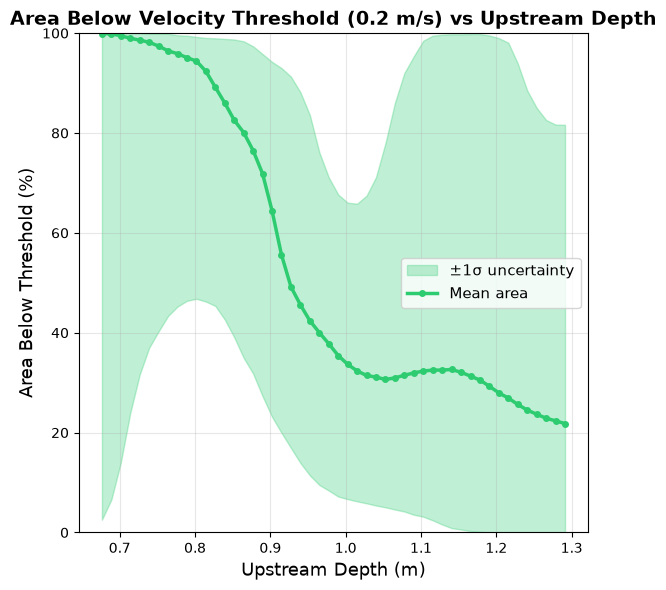

In [20]:
### 13) Area Below Threshold vs Upstream Depth
# =====================================================================
# Line plot using pre-calculated area values with uncertainty bounds
# =====================================================================

fig, ax = plt.subplots(figsize=(6, 6))

# Plot uncertainty band (±1σ based on GP model uncertainty)
ax.fill_between(upstream_depth_values, area_lower_bounds, area_upper_bounds,
                alpha=0.3, color='#2ecc71', label='±1σ uncertainty')

# Plot mean line
ax.plot(upstream_depth_values, area_below_threshold_values, 
        color='#2ecc71', linewidth=2.5, marker='o', markersize=4, label='Mean area')

ax.set_xlabel('Upstream Depth (m)', fontsize=13)
ax.set_ylabel('Area Below Threshold (%)', fontsize=13)
ax.set_title(f'Area Below Velocity Threshold ({VELOCITY_THRESHOLD} m/s) vs Upstream Depth',
             fontsize=14, fontweight='bold')
ax.set_ylim(0, 100)
ax.grid(True, alpha=0.3)
ax.legend(loc='best', fontsize=11)

plt.tight_layout()
plt.show()
